# Vecka 2 — Sampling, kvantisering, aliasing och data capture
**Syfte:** förstå digital representation av ljud i Python. Alla genererade ljud är syntetiska demonstrationer.

**Begrepp:** sampling = mätning vid diskreta tidpunkter; kvantisering = avrundning av amplitud; aliasing = felaktig frekvensrepresentation när samplingsfrekvensen är för låg. Nyquistvillkor: `fs > 2*f_max` för en bandbegränsad signal.

Antal sampel: 16000 Samplingsfrekvens: 16000 Hz


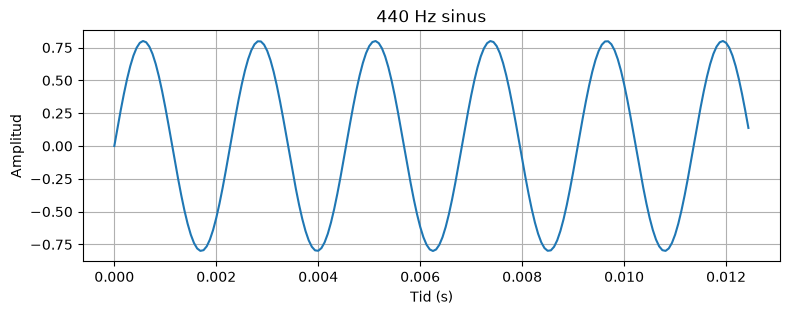

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from pathlib import Path
fs = 16000
duration = 1.0
t = np.arange(int(fs * duration)) / fs
freq = 440
signal = 0.8 * np.sin(2 * np.pi * freq * t)
print('Antal sampel:', len(signal), 'Samplingsfrekvens:', fs, 'Hz')
plt.figure(figsize=(9,3)); plt.plot(t[:200], signal[:200]); plt.xlabel('Tid (s)'); plt.ylabel('Amplitud'); plt.title('440 Hz sinus'); plt.grid(); plt.show()

## 1. Sampling
Jämför samma 440 Hz-sinus vid 16 000 Hz och 2 000 Hz. Här skapas båda signalerna analytiskt så att tidsaxlarna blir korrekta.

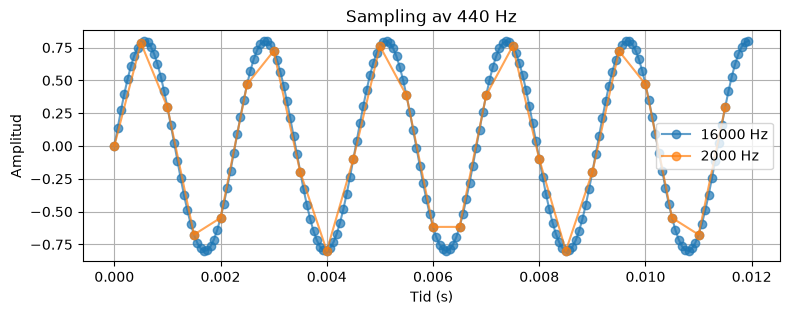

In [2]:
fig, ax = plt.subplots(figsize=(9,3))
for sample_rate in [16000, 2000]:
    ts = np.arange(int(0.012*sample_rate))/sample_rate
    xs = 0.8*np.sin(2*np.pi*440*ts)
    ax.plot(ts, xs, 'o-', label=f'{sample_rate} Hz', alpha=.7)
ax.set(xlabel='Tid (s)', ylabel='Amplitud', title='Sampling av 440 Hz'); ax.legend(); ax.grid(); plt.show()

## 2. Kvantisering
För en signal i intervallet [-1,1] ger `b` bitar `2**b` nivåer. Här mäts MSE och en enkel signal-till-kvantiseringsbrus-kvot (SQNR).

 2 bit: MSE=0.04765087, SQNR=8.27 dB
 4 bit: MSE=0.00170013, SQNR=22.75 dB
 8 bit: MSE=0.00000520, SQNR=47.89 dB
16 bit: MSE=0.00000000, SQNR=95.84 dB


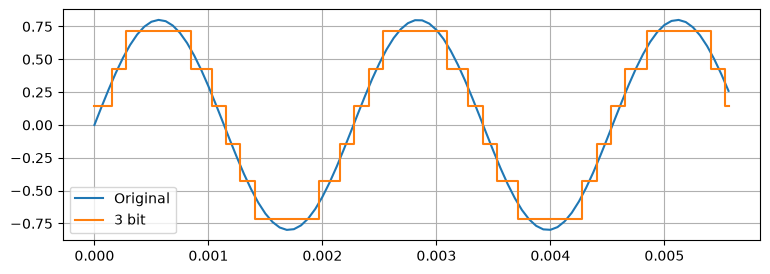

In [3]:
def quantize(x, bits):
    levels = 2**bits
    return np.round((np.clip(x,-1,1)+1)*(levels-1)/2)*2/(levels-1)-1
results=[]
for bits in [2,4,8,16]:
    q=quantize(signal,bits)
    mse=float(np.mean((signal-q)**2))
    sqnr=10*np.log10(np.mean(signal**2)/mse) if mse>0 else np.inf
    results.append((bits,mse,sqnr))
    print(f'{bits:2d} bit: MSE={mse:.8f}, SQNR={sqnr:.2f} dB')
plt.figure(figsize=(9,3)); plt.plot(t[:90],signal[:90],label='Original'); plt.step(t[:90],quantize(signal,3)[:90],where='mid',label='3 bit'); plt.legend(); plt.grid(); plt.show()

## 3. Aliasing
En sinus på 1 200 Hz samplad vid 2 000 Hz observeras som 800 Hz (|1200−2000|). Vid 8 000 Hz blir den observerade frekvensen 1 200 Hz.

In [4]:
def peak_frequency(x, rate):
    f=np.fft.rfftfreq(len(x),d=1/rate)
    amp=np.abs(np.fft.rfft(x))
    return float(f[np.argmax(amp[1:])+1])
for rate in [2000,8000]:
    tt=np.arange(rate)/rate
    xx=np.sin(2*np.pi*1200*tt)
    print(f'fs={rate} Hz -> uppmätt topp: {peak_frequency(xx,rate):.0f} Hz')
assert peak_frequency(np.sin(2*np.pi*1200*np.arange(2000)/2000),2000)==800.0

fs=2000 Hz -> uppmätt topp: 800 Hz
fs=8000 Hz -> uppmätt topp: 1200 Hz


## 4. Data capture och WAV
Spara syntetiskt exempel som PCM 16-bit, läs tillbaka och kontrollera samplingsfrekvens, kanaler, längd och amplitud. För verkliga inspelningar krävs godkännande och hantering av personuppgifter.

In [5]:
root=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
out=root/'data'/'demo_440hz.wav'; out.parent.mkdir(exist_ok=True)
pcm=(np.clip(signal,-1,1)*32767).astype(np.int16)
wavfile.write(out,fs,pcm)
read_fs,recorded=wavfile.read(out)
assert read_fs==fs and len(recorded)==len(signal) and recorded.ndim==1
normalized=recorded.astype(np.float64)/32768
print('Fil:',out,'| fs:',read_fs,'| dtype:',recorded.dtype,'| kanaler: 1','| duration:',len(recorded)/read_fs,'s')
print('Peak:',np.max(np.abs(normalized)),'| RMS:',np.sqrt(np.mean(normalized**2)))

Fil: c:\Users\bosko\Desktop\Signaton_LIA_vecka_01_02\data\demo_440hz.wav | fs: 16000 | dtype: int16 | kanaler: 1 | duration: 1.0 s
Peak: 0.799957275390625 | RMS: 0.5656530429238472


## 5. Självkontroll och slutsatser
1. Varför kan 2 000 Hz återge 440 Hz men inte 1 200 Hz korrekt?
2. Hur förändras MSE när bitdjupet ökar?
3. Varför behövs ett analogt antialiasfilter före sampling av verkligt ljud?
4. Hur kontrolleras filens format och kvalitet?

**Resultat att rapportera:** tabell med MSE/SQNR, aliasing-observation, metadata för WAV och egna reflektioner. 

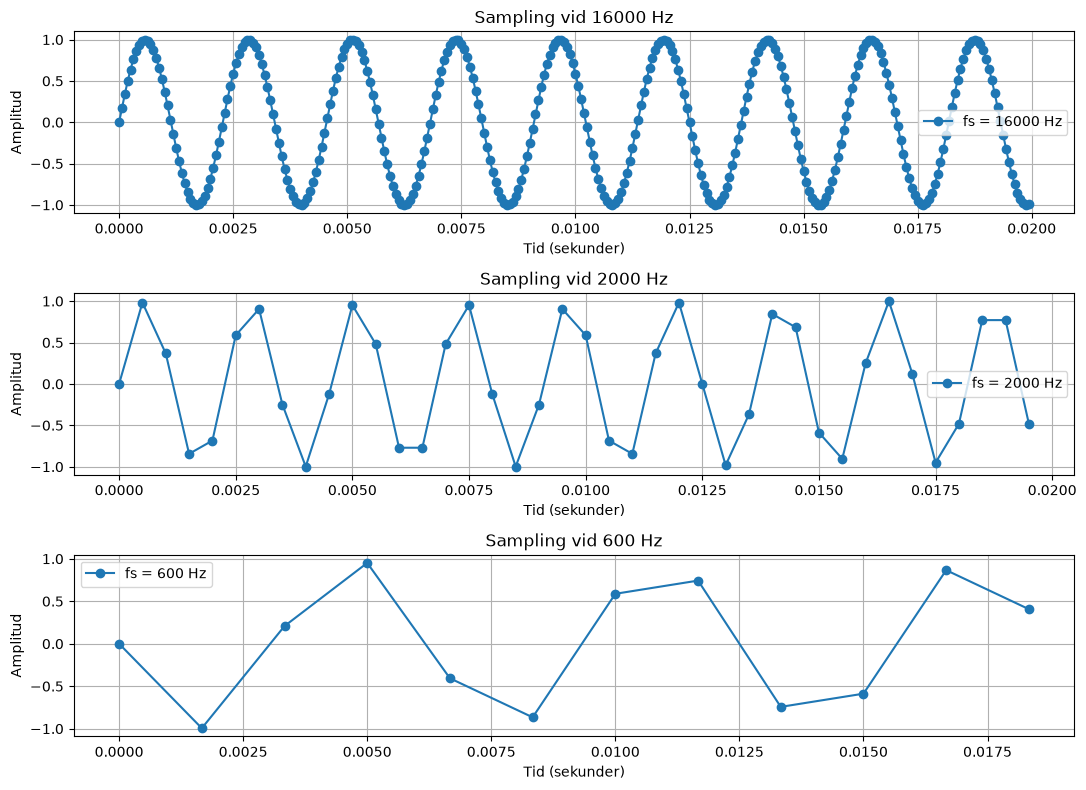

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Signalfrekvens
f_signal = 440
duration = 0.02

# Olika samplingsfrekvenser
sampling_rates = [16000, 2000, 600]

fig, axes = plt.subplots(3, 1, figsize=(11, 8))

for ax, fs in zip(axes, sampling_rates):
    t = np.arange(0, duration, 1 / fs)
    signal = np.sin(2 * np.pi * f_signal * t)

    ax.plot(t, signal, "o-", label=f"fs = {fs} Hz")
    ax.set_title(f"Sampling vid {fs} Hz")
    ax.set_xlabel("Tid (sekunder)")
    ax.set_ylabel("Amplitud")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

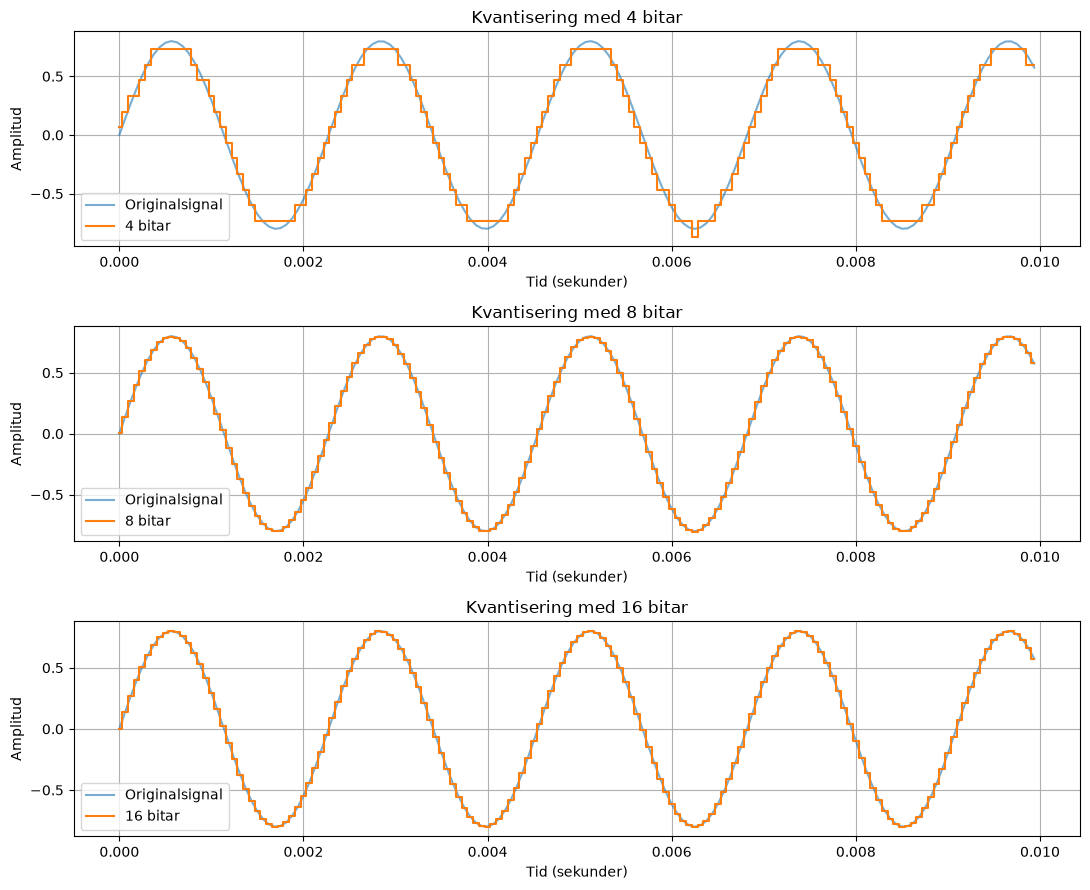

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Skapa en sinussignal
fs = 16000
duration = 0.01
freq = 440

t = np.arange(0, duration, 1 / fs)
signal = 0.8 * np.sin(2 * np.pi * freq * t)

# Kvantiseringsfunktion
def quantize(signal, bits):
    levels = 2**bits
    quantized = np.round(
        (signal + 1) / 2 * (levels - 1)
    )
    return quantized / (levels - 1) * 2 - 1

# Jämför olika bitdjup
bit_depths = [4, 8, 16]

fig, axes = plt.subplots(3, 1, figsize=(11, 9))

for ax, bits in zip(axes, bit_depths):
    quantized_signal = quantize(signal, bits)

    ax.plot(t, signal, label="Originalsignal", alpha=0.6)
    ax.step(
        t,
        quantized_signal,
        where="mid",
        label=f"{bits} bitar"
    )

    ax.set_title(f"Kvantisering med {bits} bitar")
    ax.set_xlabel("Tid (sekunder)")
    ax.set_ylabel("Amplitud")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [8]:
for bits in [4, 8, 16]:
    quantized_signal = quantize(signal, bits)

    mse = np.mean((signal - quantized_signal) ** 2)

    print(f"{bits} bitar - MSE: {mse:.8f}")

4 bitar - MSE: 0.00169877
8 bitar - MSE: 0.00000554
16 bitar - MSE: 0.00000000


Observation – Kvantisering

Vid kvantisering omvandlas signalens amplitud till ett begränsat antal diskreta nivåer. Experimentet jämför 4, 8 och 16 bitars upplösning. Ett högre bitdjup ger fler kvantiseringsnivåer och minskar normalt kvantiseringsfelet. Skillnaden kan undersökas genom att beräkna Mean Squared Error (MSE) mellan originalsignalen och den kvantiserade signalen.
 Kopiraj

## Data Capture – WAV-filer

I detta experiment skapas en syntetisk ljudsignal som
sparas som en WAV-fil och sedan läses in igen.

Syftet är att förstå hur digitala ljuddata lagras
och hanteras i Python.

In [9]:
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path

# Samplingsfrekvens och signallängd
fs = 16000
duration = 2.0
frequency = 440

# Generera en sinussignal
t = np.arange(int(fs * duration)) / fs
audio = 0.5 * np.sin(2 * np.pi * frequency * t)

# Skapa en mapp för ljudfiler
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Spara ljudsignalen som WAV
wav_path = output_dir / "test_signal_440hz.wav"

sf.write(wav_path, audio, fs, subtype="PCM_16")

print("WAV-fil sparad:", wav_path)

WAV-fil sparad: data\processed\test_signal_440hz.wav


Samplingsfrekvens: 16000 Hz
Antal sampel: 32000
Längd: 2.0 sekunder


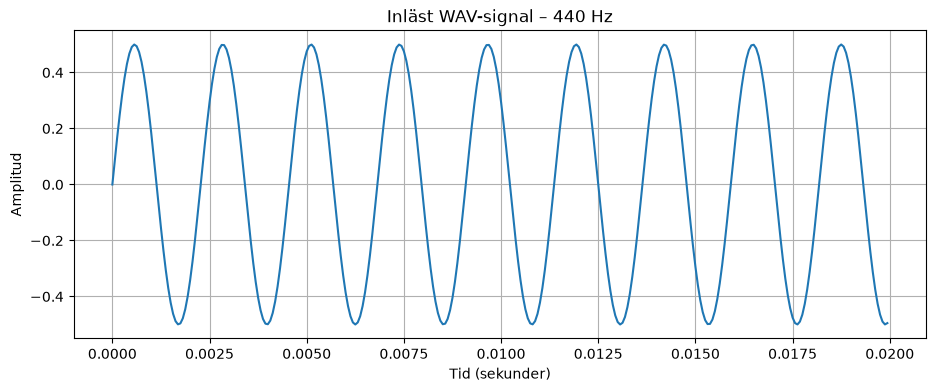

In [10]:
# Läs in WAV-filen
loaded_audio, loaded_fs = sf.read(wav_path)

print("Samplingsfrekvens:", loaded_fs, "Hz")
print("Antal sampel:", len(loaded_audio))
print("Längd:", len(loaded_audio) / loaded_fs, "sekunder")

# Visualisera de första 20 millisekunderna
samples = int(0.02 * loaded_fs)

plt.figure(figsize=(11, 4))
plt.plot(
    np.arange(samples) / loaded_fs,
    loaded_audio[:samples]
)

plt.title("Inläst WAV-signal – 440 Hz")
plt.xlabel("Tid (sekunder)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()

In [1]:
from pathlib import Path

print("Trenutni folder:", Path.cwd())

wav_files = list(Path.cwd().rglob("test_signal_440hz.wav"))

for file in wav_files:
    print("WAV fajl:", file.resolve())

Trenutni folder: c:\Users\bosko\Desktop\Signaton_LIA_vecka_01_02\notebooks
WAV fajl: C:\Users\bosko\Desktop\Signaton_LIA_vecka_01_02\notebooks\data\processed\test_signal_440hz.wav
